# Exploratory Data Analysis: Red Wine Quality

## Objectives
1. Inspect the structure and completeness of the dataset.
2. Calculate descriptive statistics for the measured variables.
3. Visualize distributions with histograms.
4. Explore relationships with scatter plots and box plots.
5. Examine numerical correlations with a heatmap and pair plot.

**Dataset:** Wine Quality (Red Wine)

The file contains physicochemical measurements and a quality score for red wine samples. This notebook focuses on exploration and interpretation, not prediction.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Kaggle: attach the CSV dataset. Local execution: keep the CSV beside this notebook.
local_path = Path("winequality-red.csv")
kaggle_matches = list(Path("/kaggle/input").rglob("winequality-red.csv")) if Path("/kaggle/input").exists() else []
data_path = kaggle_matches[0] if kaggle_matches else local_path
df = pd.read_csv(data_path, sep=";")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
print("Dataset loaded successfully.")

Rows: 1,599
Columns: 12
Dataset loaded successfully.


## 1. Initial inspection
Review the first records, column types, and missing values before plotting.

In [2]:
display(df.head())
print("\nData types:")
display(df.dtypes.rename("dtype").to_frame())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"\nMissing values: {df.isna().sum().sum()}")

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5



Data types:


,dtype
fixed acidity,float64
volatile acidity,float64
citric acid,float64
residual sugar,float64
chlorides,float64
free sulfur dioxide,float64
total sulfur dioxide,float64
density,float64
pH,float64
sulphates,float64



Duplicate rows: 240

Missing values: 0


## 2. Descriptive statistics
The summary includes count, mean, standard deviation, quartiles, minimum, and maximum.

In [3]:
display(df.describe().T.round(3))
print("\nQuality counts:")
display(df["quality"].value_counts().sort_index().rename("samples").to_frame())

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000



Quality counts:


,samples
quality,
3,10
4,53
5,681
6,638
7,199
8,18


## 3. Quality score distribution
Quality scores are discrete ratings. The plot shows how frequently each score appears.

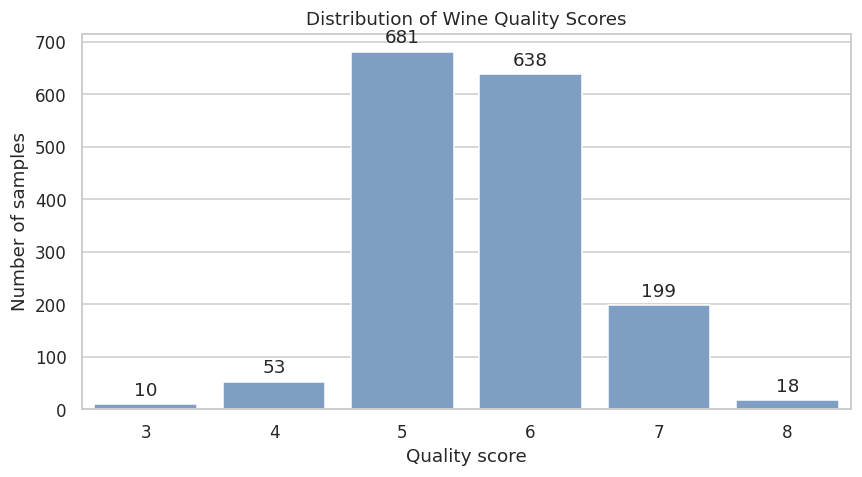

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(data=df, x="quality", order=sorted(df["quality"].unique()), color="#729fcf", ax=ax)
ax.set(title="Distribution of Wine Quality Scores", xlabel="Quality score", ylabel="Number of samples")
for container in ax.containers:
    ax.bar_label(container, padding=3)
plt.tight_layout()
plt.show()

## 4. Histograms
These histograms show the shape and spread of four variables. Skewed distributions can make the mean less representative than the median.

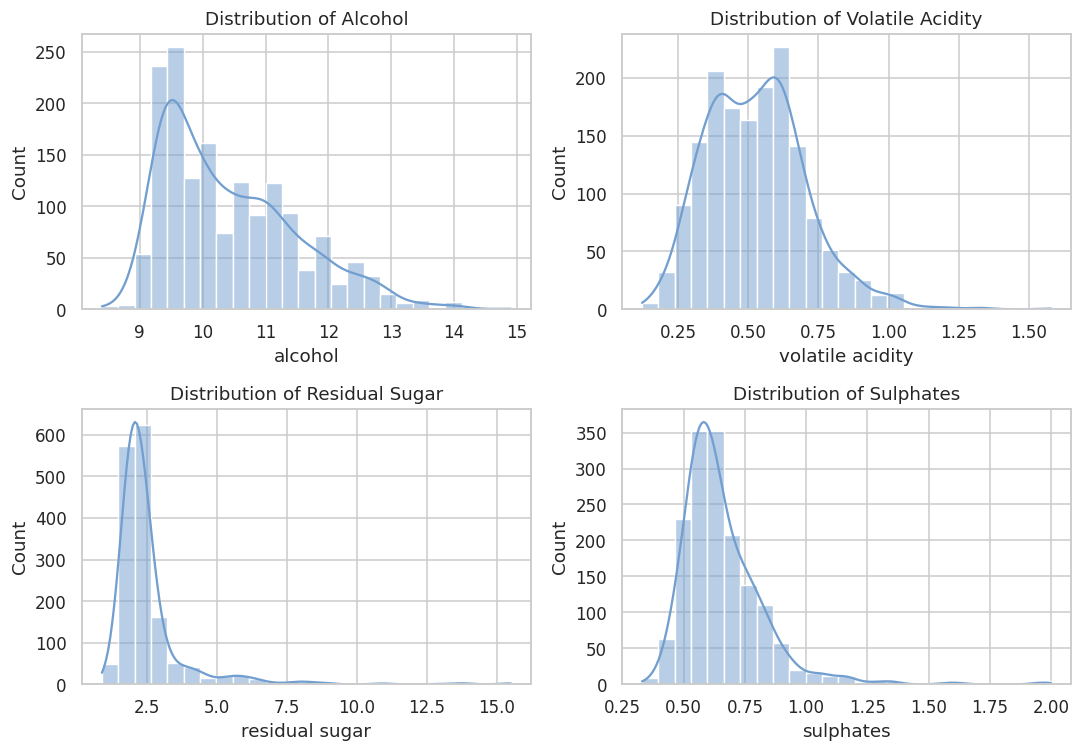

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, column in zip(axes.flat, ["alcohol", "volatile acidity", "residual sugar", "sulphates"]):
    sns.histplot(df[column], bins=25, kde=True, color="#729fcf", ax=ax)
    ax.set_title(f"Distribution of {column.title()}")
plt.tight_layout()
plt.show()

## 5. Scatter plots
Scatter plots help assess whether a measured property changes alongside the quality score. Quality is ordinal, so patterns should be interpreted as associations rather than proof of cause.

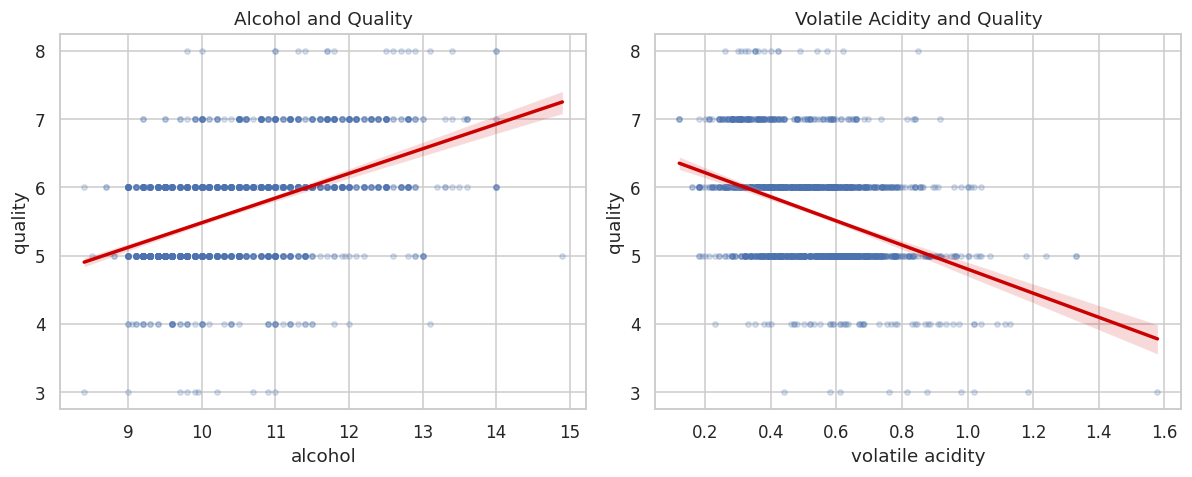

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.regplot(data=df, x="alcohol", y="quality", scatter_kws={"alpha": 0.2, "s": 12},
            line_kws={"color": "#cc0000"}, ax=axes[0])
sns.regplot(data=df, x="volatile acidity", y="quality", scatter_kws={"alpha": 0.2, "s": 12},
            line_kws={"color": "#cc0000"}, ax=axes[1])
axes[0].set_title("Alcohol and Quality")
axes[1].set_title("Volatile Acidity and Quality")
plt.tight_layout()
plt.show()

## 6. Box plots
Box plots compare medians, interquartile ranges, and potential outliers. The first pair compares properties across quality scores.

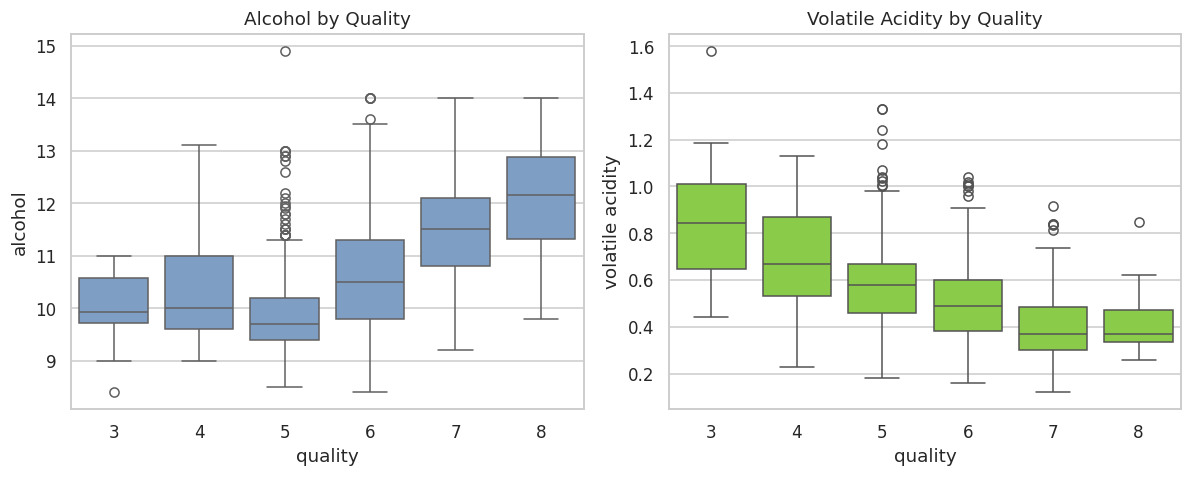

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.boxplot(data=df, x="quality", y="alcohol", color="#729fcf", ax=axes[0])
sns.boxplot(data=df, x="quality", y="volatile acidity", color="#8ae234", ax=axes[1])
axes[0].set_title("Alcohol by Quality")
axes[1].set_title("Volatile Acidity by Quality")
plt.tight_layout()
plt.show()

## 7. Outlier inspection
The box plots below highlight the spread and extreme observations in residual sugar and chlorides. An outlier is not automatically an error.

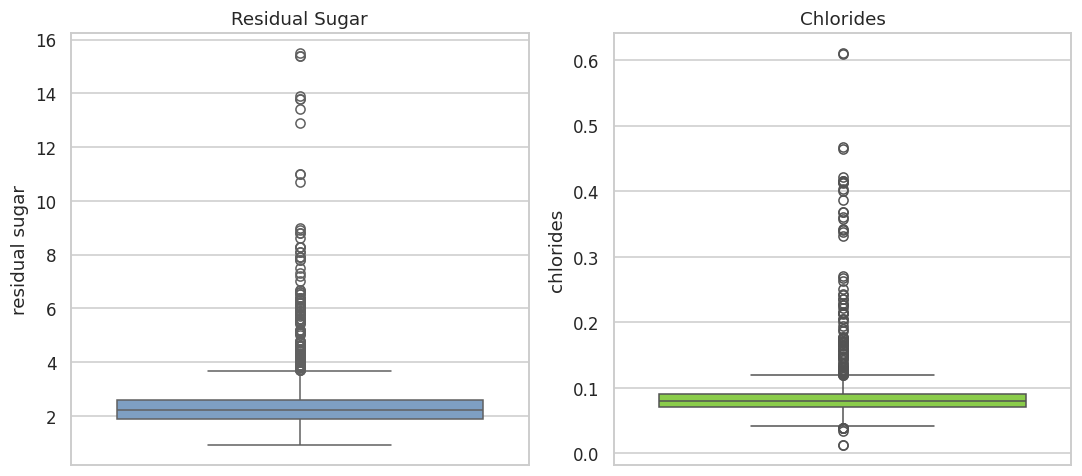

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
sns.boxplot(data=df, y="residual sugar", color="#729fcf", ax=axes[0])
sns.boxplot(data=df, y="chlorides", color="#8ae234", ax=axes[1])
axes[0].set_title("Residual Sugar")
axes[1].set_title("Chlorides")
plt.tight_layout()
plt.show()

## 8. Correlation heatmap
Pearson correlation measures linear association between numeric columns. Values near +1 indicate positive linear association, while values near -1 indicate negative linear association. Correlation does not establish causation.

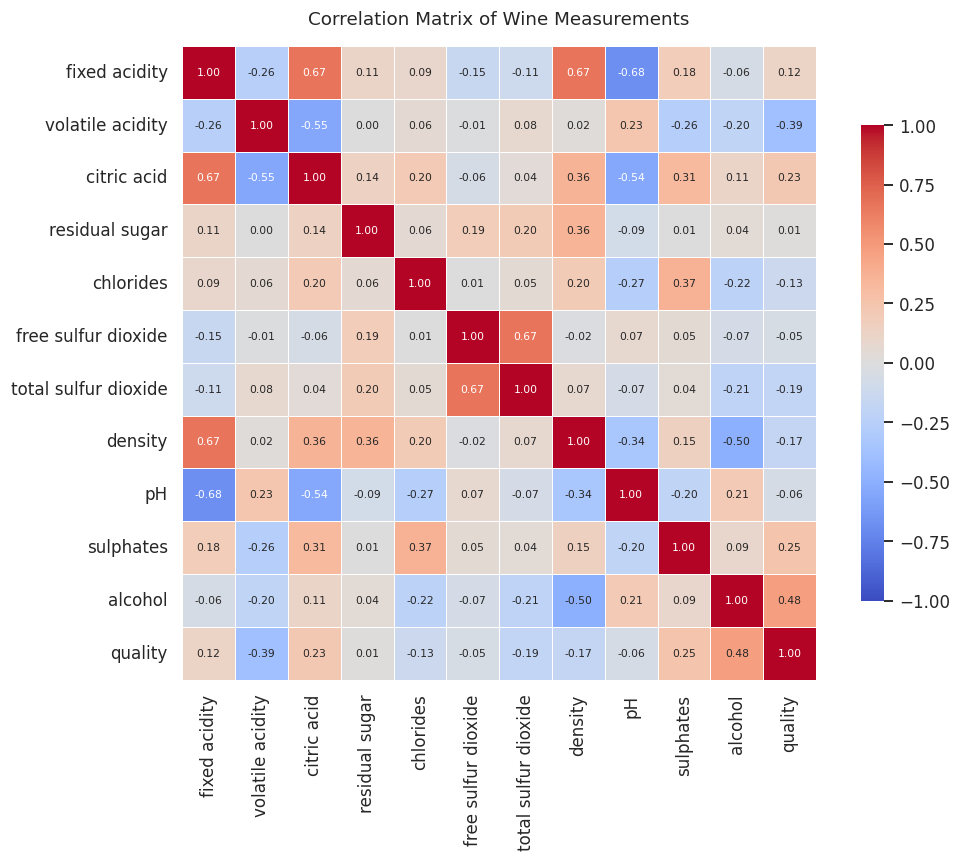

Strongest correlations with quality:


,correlation
alcohol,0.476
volatile acidity,-0.391
sulphates,0.251
citric acid,0.226
total sulfur dioxide,-0.185
density,-0.175
chlorides,-0.129
fixed acidity,0.124
pH,-0.058
free sulfur dioxide,-0.051


In [9]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.35, annot=True, fmt=".2f", annot_kws={"size": 7},
            cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation Matrix of Wine Measurements", pad=14)
plt.tight_layout()
plt.show()
print("Strongest correlations with quality:")
display(corr["quality"].drop("quality").sort_values(key=abs, ascending=False).to_frame("correlation").round(3))

## 9. Pair plot
A pair plot compares selected variables in pairs. A small subset is used to keep the relationships readable.

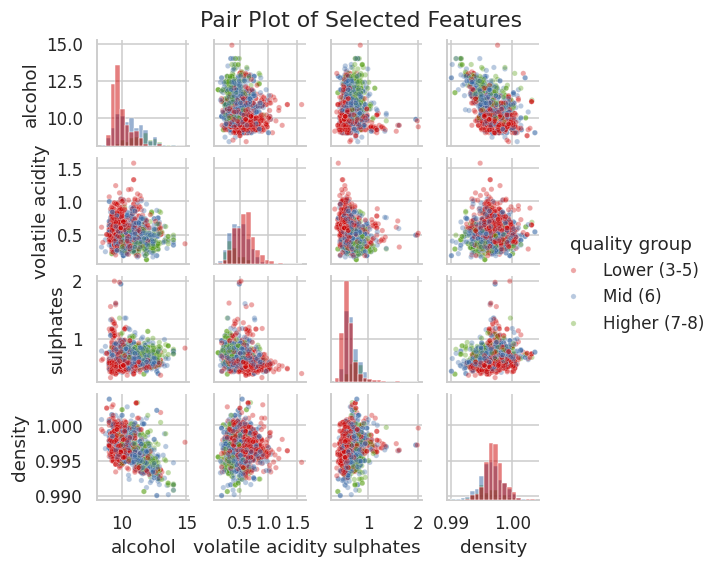

In [10]:
pair_df = df[["alcohol", "volatile acidity", "sulphates", "density", "quality"]].copy()
pair_df["quality group"] = pair_df["quality"].map(
    lambda q: "Lower (3-5)" if q <= 5 else ("Mid (6)" if q == 6 else "Higher (7-8)")
)
g = sns.pairplot(pair_df.drop(columns="quality"), hue="quality group", diag_kind="hist",
                 corner=False, plot_kws={"alpha": 0.35, "s": 12}, diag_kws={"bins": 18},
                 palette=["#cc0000", "#3465a4", "#4e9a06"], height=1.25)
g.fig.suptitle("Pair Plot of Selected Features", y=1.02)
plt.show()

## 10. Findings and conclusion
- The dataset contains 1,599 samples and 12 columns, with no missing values in the supplied file.
- Quality scores are concentrated at 5 and 6. Very low and very high scores are less common.
- Alcohol tends to increase with quality, while volatile acidity tends to decrease as quality increases.
- Residual sugar and chlorides show right-skewed distributions and high-value outliers.
- The correlation heatmap and pair plot show that several properties are associated, but these associations do not prove cause and effect.

**Conclusion:** Histograms, scatter plots, box plots, a correlation heatmap, and a pair plot reveal the main distributions, unusual values, and relationships in the red wine measurements. The results describe this dataset and should not be treated as causal conclusions.